
# Stage 2. Expert Annotation Processing

**Project:** AI Music Generation Validator

**Objective:** Transform unstructured expert comments into structured annotations for evaluating prompt-to-audio alignment.

This notebook builds on the exploratory analysis conducted in `01_data_exploration.ipynb`.

It covers:
- Rule-based comment categorization.
- Individual mismatch extraction.
- Annotation quality control.
- Prompt consistency verification.
- Preparation of a manually reviewed evaluation dataset.

All automatically extracted annotations are treated as preliminary until verified.


In [9]:

from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re

# Project paths (notebooks are located in notebooks/)
PROJECT_ROOT = Path.cwd().resolve().parent
DATA_DIR = PROJECT_ROOT / "data"

# Load original dataset
df = pd.read_csv(
    DATA_DIR / "raw" / "SunoCaps_dataset.csv"
)

# Create grouping information
df["original_id"] = (
    df["ytid_V"].str.rsplit("_", n=1).str[0]
)

df["generation_version"] = (
    df["ytid_V"].str.rsplit("_", n=1).str[-1]
)

df["prompt_type"] = df["generation_version"].map({
    "1": "Aspect List",
    "2": "Aspect List",
    "3": "Caption",
    "4": "Caption"
})

print("Dataset loaded:", df.shape)
display(df.head(3))


Dataset loaded: (256, 14)


,ytid_V,Comments,Emotion,Extra_emotion,aspect_version,caption_version,shorth_aspect,short_caption,Instrumental,aspect_list,caption,original_id,generation_version,prompt_type
0,-0Gj8-vB1q4_1,Not low quality. No strings,Sad,NaN,True,False,False,True,False,"low quality, sustained strings melody, soft fe...",The low quality recording features a ballad so...,-0Gj8-vB1q4,1,Aspect List
1,-0Gj8-vB1q4_2,Not low quality. No strings,Sad,NaN,True,False,False,True,False,"low quality, sustained strings melody, soft fe...",The low quality recording features a ballad so...,-0Gj8-vB1q4,2,Aspect List
2,-0Gj8-vB1q4_3,No strings,Sad,NaN,False,True,False,True,False,"low quality, sustained strings melody, soft fe...",The low quality recording features a ballad so...,-0Gj8-vB1q4,3,Caption


In [10]:

import re

CATEGORY_PATTERNS = {
    "genre": [
        r"\bgenre\b", r"\bpop\b", r"\brock\b",
        r"\bjazz\b", r"\bclassical\b",
        r"\bfolk\b", r"\bstyle\b"
    ],
    "instruments": [
        r"\binstruments?\b", r"\bstrings?\b",
        r"\bflute\b", r"\bbansuri\b",
        r"\bguitar\b", r"\bxylophone\b",
        r"\bbouzouki\b", r"\bpiano\b",
        r"\bdrums?\b"
    ],
    "vocals": [
        r"\bvocals?\b", r"\bvoices?\b",
        r"\bsing(?:er|ing)?\b",
        r"\blyrics?\b", r"\bwords?\b",
        r"\binstrumental\b", r"\bscat\b"
    ],
    "mood": [
        r"\bemotion", r"\bmood\b",
        r"\bsad\b", r"\bhappy\b",
        r"\benergetic\b", r"\bcalm\b"
    ],
    "tempo": [
        r"\btempo\b", r"\bbpm\b",
        r"\bfast\b", r"\bslow\b",
        r"\brhythm\b", r"\bbeat\b"
    ],
    "other": [
        r"\bquality\b", r"\brecording\b",
        r"\bwater\b", r"\bducks?\b",
        r"\bgame\b", r"\bmelody\b",
        r"\bamateur\b"
    ]
}

def categorize_comment(comment):
    if pd.isna(comment) or not str(comment).strip():
        return []

    text = str(comment).lower()

    categories = [
        category
        for category, patterns in CATEGORY_PATTERNS.items()
        if any(re.search(pattern, text) for pattern in patterns)
    ]

    return categories if categories else ["unclassified"]

df["mismatch_categories"] = df["Comments"].apply(
    categorize_comment
)

display(
    df[["Comments", "mismatch_categories"]].head(15)
)


,Comments,mismatch_categories
0,Not low quality. No strings,"[instruments, other]"
1,Not low quality. No strings,"[instruments, other]"
2,No strings,[instruments]
3,No strings. Not clearly a female voice,"[instruments, vocals]"
4,Not poor audio quality. No ambient noises,[other]
5,Not poor audio quality. No ambient noises,[other]
6,Not clearly a male singer,[vocals]
7,Not clearly a male singer,[vocals]
8,NaN,[]
9,Not clearly a male voice,[vocals]


,Count
mismatch_categories,
vocals,79
other,59
unclassified,32
instruments,28
genre,23


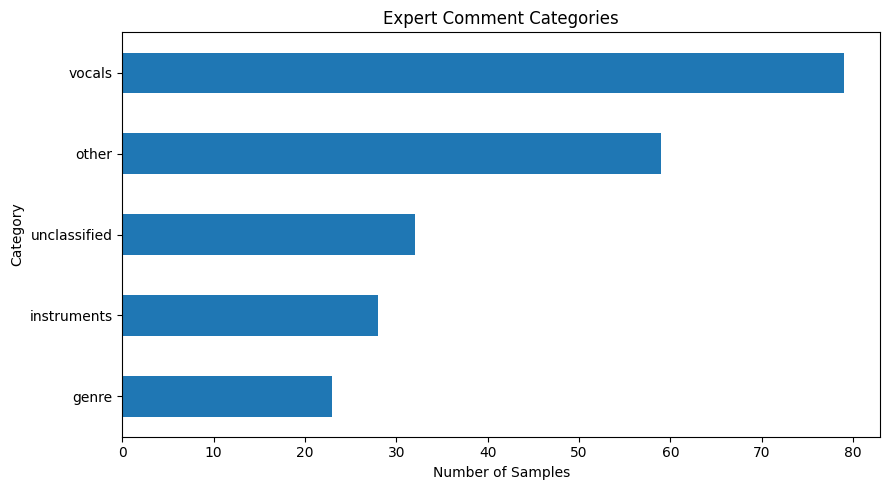

In [11]:

# Count samples mentioning each category
category_counts = (
    df["mismatch_categories"]
    .explode()
    .value_counts()
)

display(category_counts.to_frame("Count"))

plt.figure(figsize=(9, 5))

category_counts.sort_values().plot(kind="barh")

plt.xlabel("Number of Samples")
plt.ylabel("Category")
plt.title("Expert Comment Categories")
plt.tight_layout()
plt.show()


In [12]:

unclassified = df[
    df["mismatch_categories"].apply(
        lambda x: "unclassified" in x
    )
]

print("Unclassified samples:", len(unclassified))
print(
    "Unique unclassified comments:",
    unclassified["Comments"].nunique()
)

display(
    unclassified[["Comments"]]
    .drop_duplicates()
    .reset_index(drop=True)
)


Unclassified samples: 32
Unique unclassified comments: 17


,Comments
0,No noise or people talking in backgorund. Good...
1,No noise or people talking in backgorund
2,Not clearly a live performance
3,One of the few that could be considered a liv...
4,Best version that follows the prompt. Starts l...
5,No pormted noises
6,Not clearly beatbox
7,Catchy known riff
8,"No digeridoo, ambient noises included"
9,No digeridoo



### Findings

Expert feedback was mapped into preliminary mismatch categories using rule-based keyword matching.

Because comments may refer to several musical properties, the categorization supports multiple labels per sample.

However, keyword-based classification has important limitations:
- Mentioning a characteristic does not always indicate a mismatch.
- Negative statements require contextual interpretation.
- Some comments describe multiple distinct errors.
- Unclassified comments require further investigation.

The resulting labels are preliminary and should not yet be treated as verified ground truth.

Manual validation and more precise extraction of expected and observed characteristics will be required before model evaluation.


### 2.2. Improving Expert Annotation Quality

**Objective:** Refine preliminary expert comment labels by identifying previously unclassified musical characteristics and separating positive feedback from reported mismatches.

We extend the initial rule-based approach to include:
- Additional musical instruments.
- Vocal techniques and language.
- Recording and performance characteristics.
- Environmental sounds and sound effects.
- Explicit positive feedback.

The updated annotations will remain preliminary until manually reviewed.

This step improves annotation coverage before constructing the evaluation dataset.



In [13]:

ADDITIONAL_PATTERNS = {
    "instruments": [
        r"\bdigeridoo\b", r"\bdidgeridoo\b",
        r"\bharmonica\b", r"\bwoodwinds?\b",
        r"\bviolins?\b"
    ],
    "vocals": [
        r"\bbeatbox\b",
        r"\btalking\b",
        r"\blanguage\b",
        r"\bdutch\b"
    ],
    "other": [
        r"\bnoise", r"\bambient\b",
        r"\blive performance\b",
        r"\bpeople\b", r"\bglass shattering\b",
        r"\bshort\b", r"\bpormted\b",
        r"\bclapping\b"
    ]
}

# Merge additional patterns
UPDATED_PATTERNS = {
    category: (
        CATEGORY_PATTERNS.get(category, [])
        + ADDITIONAL_PATTERNS.get(category, [])
    )
    for category in CATEGORY_PATTERNS
}

POSITIVE_PATTERNS = [
    r"\bfollows well\b",
    r"\bfollows the prompt\b",
    r"\bbest version\b",
    r"\bgood (?:indian )?vibe\b"
]


In [14]:

def categorize_comment_v2(comment):
    if pd.isna(comment) or not str(comment).strip():
        return {
            "categories": [],
            "feedback_status": "missing"
        }

    text = str(comment).lower()

    categories = [
        category
        for category, patterns in UPDATED_PATTERNS.items()
        if any(re.search(pattern, text) for pattern in patterns)
    ]

    positive = any(
        re.search(pattern, text)
        for pattern in POSITIVE_PATTERNS
    )

    # Positive statements may coexist with reported errors.
    has_negative_cue = bool(re.search(
        r"\b(no|not|missing|instead|added|"
        r"does not|don't|but|far from)\b",
        text
    ))

    if positive and not has_negative_cue:
        status = "positive"
    elif positive and has_negative_cue:
        status = "mixed"
    elif categories:
        status = "potential_mismatch"
    else:
        status = "needs_review"

    return {
        "categories": categories,
        "feedback_status": status
    }


annotation_results = df["Comments"].apply(
    categorize_comment_v2
)

df["mismatch_categories_v2"] = annotation_results.apply(
    lambda x: x["categories"]
)

df["feedback_status"] = annotation_results.apply(
    lambda x: x["feedback_status"]
)

display(
    df[
        ["Comments", "mismatch_categories_v2",
         "feedback_status"]
    ].head(20)
)


,Comments,mismatch_categories_v2,feedback_status
0,Not low quality. No strings,"[instruments, other]",potential_mismatch
1,Not low quality. No strings,"[instruments, other]",potential_mismatch
2,No strings,[instruments],potential_mismatch
3,No strings. Not clearly a female voice,"[instruments, vocals]",potential_mismatch
4,Not poor audio quality. No ambient noises,[other],potential_mismatch
5,Not poor audio quality. No ambient noises,[other],potential_mismatch
6,Not clearly a male singer,[vocals],potential_mismatch
7,Not clearly a male singer,[vocals],potential_mismatch
8,NaN,[],missing
9,Not clearly a male voice,[vocals],potential_mismatch


In [15]:

# Feedback status distribution
print("Feedback status distribution:")
display(
    df["feedback_status"]
    .value_counts()
    .to_frame("Count")
)

# Comments requiring manual review
print("\nComments requiring manual review:")

review_comments = df.loc[
    df["feedback_status"].isin(["needs_review", "mixed"]),
    ["Comments", "mismatch_categories_v2", "feedback_status"]
].drop_duplicates(subset=["Comments"])

display(review_comments.reset_index(drop=True))



Feedback status distribution:


,Count
feedback_status,
potential_mismatch,174
missing,73
positive,4
mixed,4
needs_review,1



Comments requiring manual review:


,Comments,mismatch_categories_v2,feedback_status
0,Catchy known riff,[],needs_review
1,Follows well the low quality and weird prompts...,"[vocals, other]",mixed
2,Follows well the dutch language prompt. No acc...,[vocals],mixed


#### Findings

The initial annotation process identified 174 potential mismatches, 73 samples without expert feedback, 4 positive comments, 4 mixed comments, and 1 comment requiring further review.

These results demonstrate that expert feedback contains both negative and positive assessments.

However, the rule-based classification remains preliminary. Some categories overlap, and positive statements may coexist with specific mismatches.

Before using these annotations as ground truth, we need to manually review ambiguous comments and improve the classification rules.


### 2.3. Structured Expert Annotation Dataset

**Objective:** Prepare a structured annotation dataset for evaluating prompt-to-audio alignment.

Expert comments may describe multiple musical characteristics and contain both positive and negative observations.

We define the following annotation fields:
- `track_id`: Unique identifier of the generated track.
- `category`: Musical characteristic being evaluated.
- `expected`: Characteristic requested in the prompt.
- `observed`: Characteristic reported by the expert.
- `error_type`: Type of mismatch (missing, added, replaced, incorrect).
- `annotation_status`: Whether the annotation has been manually verified.

At this stage, we prepare an annotation template rather than automatically assigning definitive ground-truth labels.


In [16]:

annotations = df[
    [
        "ytid_V",
        "original_id",
        "generation_version",
        "caption",
        "aspect_list",
        "Comments",
        "mismatch_categories_v2",
        "feedback_status"
    ]
].copy()

annotations = annotations.explode(
    "mismatch_categories_v2"
)

annotations = annotations.rename(columns={
    "ytid_V": "track_id",
    "Comments": "expert_comment",
    "mismatch_categories_v2": "category"
})

annotations["expected"] = pd.NA
annotations["observed"] = pd.NA
annotations["error_type"] = pd.NA
annotations["annotation_status"] = "unreviewed"

display(annotations.head(10))

print("Total annotation rows:", len(annotations))


,track_id,original_id,generation_version,caption,aspect_list,expert_comment,category,feedback_status,expected,observed,error_type,annotation_status
0,-0Gj8-vB1q4_1,-0Gj8-vB1q4,1,The low quality recording features a ballad so...,"low quality, sustained strings melody, soft fe...",Not low quality. No strings,instruments,potential_mismatch,<NA>,<NA>,<NA>,unreviewed
0,-0Gj8-vB1q4_1,-0Gj8-vB1q4,1,The low quality recording features a ballad so...,"low quality, sustained strings melody, soft fe...",Not low quality. No strings,other,potential_mismatch,<NA>,<NA>,<NA>,unreviewed
1,-0Gj8-vB1q4_2,-0Gj8-vB1q4,2,The low quality recording features a ballad so...,"low quality, sustained strings melody, soft fe...",Not low quality. No strings,instruments,potential_mismatch,<NA>,<NA>,<NA>,unreviewed
1,-0Gj8-vB1q4_2,-0Gj8-vB1q4,2,The low quality recording features a ballad so...,"low quality, sustained strings melody, soft fe...",Not low quality. No strings,other,potential_mismatch,<NA>,<NA>,<NA>,unreviewed
2,-0Gj8-vB1q4_3,-0Gj8-vB1q4,3,The low quality recording features a ballad so...,"low quality, sustained strings melody, soft fe...",No strings,instruments,potential_mismatch,<NA>,<NA>,<NA>,unreviewed
3,-0Gj8-vB1q4_4,-0Gj8-vB1q4,4,The low quality recording features a ballad so...,"low quality, sustained strings melody, soft fe...",No strings. Not clearly a female voice,instruments,potential_mismatch,<NA>,<NA>,<NA>,unreviewed
3,-0Gj8-vB1q4_4,-0Gj8-vB1q4,4,The low quality recording features a ballad so...,"low quality, sustained strings melody, soft fe...",No strings. Not clearly a female voice,vocals,potential_mismatch,<NA>,<NA>,<NA>,unreviewed
4,-1UWSisR2zo_1,-1UWSisR2zo,1,A male singer sings this groovy melody. The so...,"live performance, poor audio quality, ambient ...",Not poor audio quality. No ambient noises,other,potential_mismatch,<NA>,<NA>,<NA>,unreviewed
5,-1UWSisR2zo_2,-1UWSisR2zo,2,A male singer sings this groovy melody. The so...,"live performance, poor audio quality, ambient ...",Not poor audio quality. No ambient noises,other,potential_mismatch,<NA>,<NA>,<NA>,unreviewed
6,-1UWSisR2zo_3,-1UWSisR2zo,3,A male singer sings this groovy melody. The so...,"live performance, poor audio quality, ambient ...",Not clearly a male singer,vocals,potential_mismatch,<NA>,<NA>,<NA>,unreviewed


Total annotation rows: 310


In [17]:

# Inspect available annotation categories
print("Category distribution:")
display(
    annotations["category"]
    .value_counts(dropna=False)
    .to_frame("Count")
)

# Check annotation coverage
print("\nUnique tracks:")
print(annotations["track_id"].nunique())

print("\nAnnotation status:")
display(
    annotations["annotation_status"]
    .value_counts()
    .to_frame("Count")
)

# Inspect example annotations
display(
    annotations[
        [
            "track_id",
            "expert_comment",
            "category",
            "expected",
            "observed",
            "error_type"
        ]
    ].head(15)
)


Category distribution:


,Count
category,
vocals,93
other,83
NaN,75
instruments,36
genre,23



Unique tracks:
256

Annotation status:


,Count
annotation_status,
unreviewed,310


,track_id,expert_comment,category,expected,observed,error_type
0,-0Gj8-vB1q4_1,Not low quality. No strings,instruments,<NA>,<NA>,<NA>
0,-0Gj8-vB1q4_1,Not low quality. No strings,other,<NA>,<NA>,<NA>
1,-0Gj8-vB1q4_2,Not low quality. No strings,instruments,<NA>,<NA>,<NA>
1,-0Gj8-vB1q4_2,Not low quality. No strings,other,<NA>,<NA>,<NA>
2,-0Gj8-vB1q4_3,No strings,instruments,<NA>,<NA>,<NA>
3,-0Gj8-vB1q4_4,No strings. Not clearly a female voice,instruments,<NA>,<NA>,<NA>
3,-0Gj8-vB1q4_4,No strings. Not clearly a female voice,vocals,<NA>,<NA>,<NA>
4,-1UWSisR2zo_1,Not poor audio quality. No ambient noises,other,<NA>,<NA>,<NA>
5,-1UWSisR2zo_2,Not poor audio quality. No ambient noises,other,<NA>,<NA>,<NA>
6,-1UWSisR2zo_3,Not clearly a male singer,vocals,<NA>,<NA>,<NA>


In [18]:

from pathlib import Path

output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

annotations.to_csv(
    output_dir / "expert_annotations_draft.csv",
    index=False
)

print("Draft annotation dataset saved successfully.")


Draft annotation dataset saved successfully.



### Findings

A preliminary structured annotation dataset was created from the expert comments.

Each generated track is linked to its original prompt, expert feedback, and candidate mismatch categories.

Additional fields were introduced to support detailed error analysis, including expected and observed characteristics, error types, and annotation verification status.

The resulting dataset is an intermediate annotation template, not yet verified ground truth.

The next step is to extract individual mismatch statements and assign more precise labels before evaluating audio-based predictions.


### 2.4. Extracting Individual Mismatch Statements

**Objective:** Convert expert comments into individual, interpretable mismatch records.

The previous step assigned broad musical categories to each comment. However, a single comment may describe several independent deviations from the original prompt.

In this step, we introduce rule-based extraction of specific mismatch statements.

Each extracted issue includes:
- The affected musical category.
- The expected characteristic.
- The observed characteristic.
- The type of mismatch.

This initial extraction focuses on clearly identifiable patterns. Ambiguous statements are preserved for manual review rather than automatically assigned potentially incorrect labels.


In [19]:

import re

MISMATCH_RULES = [
    {
        "pattern": r"\bno strings\b",
        "category": "instruments",
        "expected": "strings",
        "observed": "absent",
        "error_type": "missing"
    },
    {
        "pattern": r"\bno xylophone\b",
        "category": "instruments",
        "expected": "xylophone",
        "observed": "absent",
        "error_type": "missing"
    },
    {
        "pattern": r"\bno harmonica\b",
        "category": "instruments",
        "expected": "harmonica",
        "observed": "absent",
        "error_type": "missing"
    },
    {
        "pattern": r"\bno (?:digeridoo|didgeridoo)\b",
        "category": "instruments",
        "expected": "didgeridoo",
        "observed": "absent",
        "error_type": "missing"
    },
    {
        "pattern": r"\badded voice\b",
        "category": "vocals",
        "expected": "no vocals",
        "observed": "vocals present",
        "error_type": "added"
    },
    {
        "pattern": r"\bnot clearly a male (?:voice|vocal|singer)\b",
        "category": "vocals",
        "expected": "male vocals",
        "observed": "unclear vocal type",
        "error_type": "incorrect"
    },
    {
        "pattern": r"\bnot clearly a female (?:voice|vocal|singer)\b",
        "category": "vocals",
        "expected": "female vocals",
        "observed": "unclear vocal type",
        "error_type": "incorrect"
    },
    {
        "pattern": r"\bnot (?:low|poor) (?:audio )?quality\b",
        "category": "other",
        "expected": "low recording quality",
        "observed": "higher recording quality",
        "error_type": "incorrect"
    },
    {
        "pattern": r"\bno ambient noises?\b",
        "category": "other",
        "expected": "ambient noise",
        "observed": "absent",
        "error_type": "missing"
    }
]

def extract_mismatches(comment):
    if pd.isna(comment) or not str(comment).strip():
        return []

    text = str(comment).lower()
    results = []

    for rule in MISMATCH_RULES:
        for match in re.finditer(rule["pattern"], text):
            results.append({
                "category": rule["category"],
                "expected": rule["expected"],
                "observed": rule["observed"],
                "error_type": rule["error_type"],
                "evidence": match.group(0),
                "annotation_status": "auto_extracted"
            })

    return results


df["extracted_mismatches"] = df["Comments"].apply(
    extract_mismatches
)

display(
    df[["ytid_V", "Comments", "extracted_mismatches"]].head(10)
)


,ytid_V,Comments,extracted_mismatches
0,-0Gj8-vB1q4_1,Not low quality. No strings,"[{'category': 'instruments', 'expected': 'stri..."
1,-0Gj8-vB1q4_2,Not low quality. No strings,"[{'category': 'instruments', 'expected': 'stri..."
2,-0Gj8-vB1q4_3,No strings,"[{'category': 'instruments', 'expected': 'stri..."
3,-0Gj8-vB1q4_4,No strings. Not clearly a female voice,"[{'category': 'instruments', 'expected': 'stri..."
4,-1UWSisR2zo_1,Not poor audio quality. No ambient noises,"[{'category': 'other', 'expected': 'low record..."
5,-1UWSisR2zo_2,Not poor audio quality. No ambient noises,"[{'category': 'other', 'expected': 'low record..."
6,-1UWSisR2zo_3,Not clearly a male singer,"[{'category': 'vocals', 'expected': 'male voca..."
7,-1UWSisR2zo_4,Not clearly a male singer,"[{'category': 'vocals', 'expected': 'male voca..."
8,-5xOcMJpTUk_1,NaN,[]
9,-5xOcMJpTUk_2,Not clearly a male voice,"[{'category': 'vocals', 'expected': 'male voca..."


In [20]:

# Keep one row per extracted mismatch
mismatch_df = df[
    ["ytid_V", "Comments", "extracted_mismatches"]
].explode("extracted_mismatches")

# Remove tracks with no extracted issues
mismatch_df = mismatch_df.dropna(
    subset=["extracted_mismatches"]
).copy()

# Expand extracted dictionaries into columns
details = pd.json_normalize(
    mismatch_df["extracted_mismatches"].tolist()
)

mismatch_df = pd.concat(
    [
        mismatch_df[["ytid_V", "Comments"]].reset_index(drop=True),
        details
    ],
    axis=1
)

mismatch_df = mismatch_df.rename(columns={
    "ytid_V": "track_id",
    "Comments": "expert_comment"
})

display(mismatch_df.head(15))

print("Total extracted mismatch records:", len(mismatch_df))
print("Tracks with extracted mismatches:", mismatch_df["track_id"].nunique())


,track_id,expert_comment,category,expected,observed,error_type,evidence,annotation_status
0,-0Gj8-vB1q4_1,Not low quality. No strings,instruments,strings,absent,missing,no strings,auto_extracted
1,-0Gj8-vB1q4_1,Not low quality. No strings,other,low recording quality,higher recording quality,incorrect,not low quality,auto_extracted
2,-0Gj8-vB1q4_2,Not low quality. No strings,instruments,strings,absent,missing,no strings,auto_extracted
3,-0Gj8-vB1q4_2,Not low quality. No strings,other,low recording quality,higher recording quality,incorrect,not low quality,auto_extracted
4,-0Gj8-vB1q4_3,No strings,instruments,strings,absent,missing,no strings,auto_extracted
5,-0Gj8-vB1q4_4,No strings. Not clearly a female voice,instruments,strings,absent,missing,no strings,auto_extracted
6,-0Gj8-vB1q4_4,No strings. Not clearly a female voice,vocals,female vocals,unclear vocal type,incorrect,not clearly a female voice,auto_extracted
7,-1UWSisR2zo_1,Not poor audio quality. No ambient noises,other,low recording quality,higher recording quality,incorrect,not poor audio quality,auto_extracted
8,-1UWSisR2zo_1,Not poor audio quality. No ambient noises,other,ambient noise,absent,missing,no ambient noises,auto_extracted
9,-1UWSisR2zo_2,Not poor audio quality. No ambient noises,other,low recording quality,higher recording quality,incorrect,not poor audio quality,auto_extracted


Total extracted mismatch records: 76
Tracks with extracted mismatches: 67


In [21]:

# Samples with non-empty expert comments
has_comment = (
    df["Comments"].notna()
    & df["Comments"].astype("string").str.strip().ne("")
)

has_extraction = df["extracted_mismatches"].apply(
    lambda x: len(x) > 0
)

n_comments = int(has_comment.sum())
n_extracted = int((has_comment & has_extraction).sum())

coverage = (
    n_extracted / n_comments * 100
    if n_comments > 0 else 0
)

print(f"Tracks with expert comments: {n_comments}")
print(f"Tracks with extracted issues: {n_extracted}")
print(f"Extraction coverage: {coverage:.2f}%")

print("\nComments not covered by extraction rules:")

uncovered = df.loc[
    has_comment & ~has_extraction,
    ["Comments"]
].drop_duplicates()

display(uncovered.reset_index(drop=True))


Tracks with expert comments: 183
Tracks with extracted issues: 67
Extraction coverage: 36.61%

Comments not covered by extraction rules:


,Comments
0,"Good indian ""vibe"" particularly v3 and 4. But ..."
1,"Does not follow ""instrumental"" text command."
2,"Does not follow ""low quality"" text command or ..."
3,"Does not follow ""low quality"" text command or ..."
4,No noise or people talking in backgorund. Good...
5,No noise or people talking in backgorund
6,Not clearly a live performance
7,One of the few that could be considered a liv...
8,Not clearly male voices. Nice vibrato on the v...
9,Not clearly male voices. One of the few that c...



### Findings

A rule-based mismatch extraction module was introduced to convert selected expert observations into structured records.

Unlike broad category classification, this approach supports multiple individual errors per generated track.

The extracted records specify expected and observed musical characteristics, error types, and supporting text evidence.

Extraction coverage is measured to assess how much of the available expert feedback can be processed by the initial rules.

The extracted labels remain provisional and will require prompt consistency checks and manual verification before use as ground truth.


### 2.5. Improving Mismatch Extraction Coverage

**Objective:** Extend the rule-based extraction system to recognize additional explicit discrepancies in expert comments.

The initial extractor identified 76 mismatch records across 67 tracks, covering 36.61% of samples with expert feedback.

We now extend the extractor to recognize:
- Violations of instrumental-only requirements.
- Missing or incorrectly specified vocal characteristics.
- Missing musical instruments.
- Unexpected lyrics or vocal content.
- Missing environmental sounds.

The new rules focus on explicit statements to limit false positives.

Extraction coverage measures annotation completeness, not classification accuracy. Extracted mismatches still require verification against the original prompt.


In [22]:

ADDITIONAL_MISMATCH_RULES = [
    # Instrumental requirements
    {
        "pattern": r"does not follow [\"']?instrumental",
        "category": "vocals",
        "expected": "instrumental only",
        "observed": "instrumental requirement violated",
        "error_type": "incorrect"
    },
    {
        "pattern": r"\bnot instrumental\b",
        "category": "vocals",
        "expected": "instrumental only",
        "observed": "non-instrumental audio",
        "error_type": "incorrect"
    },

    # Vocal characteristics
    {
        "pattern": r"\bnot clearly female voice\b",
        "category": "vocals",
        "expected": "female vocals",
        "observed": "unclear vocal type",
        "error_type": "incorrect"
    },
    {
        "pattern": r"\bnot clearly male voices\b",
        "category": "vocals",
        "expected": "male vocals",
        "observed": "unclear vocal type",
        "error_type": "incorrect"
    },

    # Missing instruments
    {
        "pattern": r"\bno irish bouzouki\b",
        "category": "instruments",
        "expected": "irish bouzouki",
        "observed": "absent",
        "error_type": "missing"
    },
    {
        "pattern": r"\bno bansuri flute\b",
        "category": "instruments",
        "expected": "bansuri flute",
        "observed": "absent",
        "error_type": "missing"
    },
    {
        "pattern": r"\bno woodwinds or violins\b",
        "category": "instruments",
        "expected": "woodwinds and violins",
        "observed": "absent",
        "error_type": "missing"
    },

    # Environmental sounds
    {
        "pattern": r"\bno sound of water\b",
        "category": "other",
        "expected": "water sounds",
        "observed": "absent",
        "error_type": "missing"
    },
    {
        "pattern": r"\bno ducks\b",
        "category": "other",
        "expected": "duck sounds",
        "observed": "absent",
        "error_type": "missing"
    },
    {
        "pattern": r"\bno glass shattering\b",
        "category": "other",
        "expected": "glass shattering",
        "observed": "absent",
        "error_type": "missing"
    }
]

# Create an extended rule set
ALL_MISMATCH_RULES = (
    MISMATCH_RULES + ADDITIONAL_MISMATCH_RULES
)

print("Total extraction rules:", len(ALL_MISMATCH_RULES))


Total extraction rules: 19


In [23]:

def extract_mismatches_v2(comment, rules=ALL_MISMATCH_RULES):
    if pd.isna(comment) or not str(comment).strip():
        return []

    text = str(comment).lower()
    results = []
    seen = set()

    for rule in rules:
        for match in re.finditer(rule["pattern"], text):
            key = (
                rule["category"],
                rule["expected"],
                rule["error_type"],
                match.start(),
                match.end()
            )

            if key in seen:
                continue

            seen.add(key)

            results.append({
                "category": rule["category"],
                "expected": rule["expected"],
                "observed": rule["observed"],
                "error_type": rule["error_type"],
                "evidence": match.group(0),
                "annotation_status": "auto_extracted"
            })

    return results


df["extracted_mismatches_v2"] = df["Comments"].apply(
    extract_mismatches_v2
)


In [24]:

has_comment = (
    df["Comments"].notna()
    & df["Comments"].astype("string").str.strip().ne("")
).fillna(False)

v1_extracted = df["extracted_mismatches"].apply(
    lambda x: len(x) > 0
)

v2_extracted = df["extracted_mismatches_v2"].apply(
    lambda x: len(x) > 0
)

n_comments = int(has_comment.sum())

comparison = pd.DataFrame({
    "Version": ["Initial extractor", "Extended extractor"],
    "Covered Tracks": [
        int((has_comment & v1_extracted).sum()),
        int((has_comment & v2_extracted).sum())
    ],
    "Extracted Issues": [
        df["extracted_mismatches"].apply(len).sum(),
        df["extracted_mismatches_v2"].apply(len).sum()
    ]
})

comparison["Coverage (%)"] = (
    comparison["Covered Tracks"] / n_comments * 100
).round(2)

display(comparison)

# Remaining uncovered comments
remaining = df.loc[
    has_comment & ~v2_extracted,
    ["Comments"]
].drop_duplicates()

print("Remaining unique uncovered comments:", len(remaining))
display(remaining.reset_index(drop=True))


,Version,Covered Tracks,Extracted Issues,Coverage (%)
0,Initial extractor,67,76,36.61
1,Extended extractor,104,117,56.83


Remaining unique uncovered comments: 42


,Comments
0,"Good indian ""vibe"" particularly v3 and 4. But ..."
1,"Does not follow ""low quality"" text command or ..."
2,"Does not follow ""low quality"" text command or ..."
3,No noise or people talking in backgorund. Good...
4,No noise or people talking in backgorund
5,Not clearly a live performance
6,One of the few that could be considered a liv...
7,Follows very well the no-lyrics only vocables ...
8,The violins do not follow the eight note patte...
9,a lot of instruments not specified are added f...


In [25]:

# Compare extracted issues across prompt representations
df["n_mismatches"] = df[
    "extracted_mismatches_v2"
].apply(len)

mismatch_summary = (
    df.groupby("prompt_type")
    .agg(
        tracks=("ytid_V", "count"),
        tracks_with_extracted_issues=(
            "n_mismatches",
            lambda x: (x > 0).sum()
        ),
        total_extracted_issues=("n_mismatches", "sum"),
        mean_issues_per_track=("n_mismatches", "mean")
    )
)

display(mismatch_summary.round(2))

,tracks,tracks_with_extracted_issues,total_extracted_issues,mean_issues_per_track
prompt_type,,,,
Aspect List,128,49,57,0.45
Caption,128,55,60,0.47



### Findings

The extraction system was extended with additional rules for explicit vocal, instrumental, and environmental sound mismatches.

The updated extractor is compared with the initial version using:
- Number of tracks with extracted issues.
- Total number of extracted mismatch records.
- Percentage of commented tracks covered.

Increasing extraction coverage is useful, but it does not guarantee improved annotation accuracy.

Some expert comments remain ambiguous or contain complex statements requiring more advanced semantic interpretation.

These cases will be reviewed before constructing the final evaluation labels.


### 2.6. Annotation Quality Control

**Objective:** Assess the reliability of automatically extracted mismatch annotations before using them for model evaluation.

The extended rule-based extractor identified 117 candidate mismatch records across 104 tracks, achieving 56.83% track-level coverage among samples with expert comments.

We now examine whether extracted expectations are consistent with the original prompts and identify overlapping or potentially ambiguous annotations.

This quality-control step helps prevent incorrect labels from contaminating the evaluation dataset.


In [26]:

# Expand V2 extractions into individual records
qc_df = df[
    ["ytid_V", "caption", "aspect_list", "Comments",
     "extracted_mismatches_v2"]
].explode("extracted_mismatches_v2")

qc_df = qc_df.dropna(
    subset=["extracted_mismatches_v2"]
).copy()

details = pd.json_normalize(
    qc_df["extracted_mismatches_v2"].tolist()
)

qc_df = pd.concat(
    [
        qc_df.drop(columns=["extracted_mismatches_v2"])
        .reset_index(drop=True),
        details
    ],
    axis=1
)

# Identify generation version
qc_df["generation_version"] = (
    qc_df["ytid_V"]
    .str.rsplit("_", n=1)
    .str[-1]
)

# Determine prompt type
qc_df["prompt_type"] = qc_df["generation_version"].map({
    "1": "aspect_list",
    "2": "aspect_list",
    "3": "caption",
    "4": "caption"
})

# Select the corresponding prompt
qc_df["prompt_text"] = qc_df.apply(
    lambda row: (
        row["aspect_list"]
        if row["prompt_type"] == "aspect_list"
        else row["caption"]
    ),
    axis=1
).fillna("").str.lower()

display(
    qc_df[[
        "ytid_V",
        "generation_version",
        "prompt_type",
        "prompt_text"
    ]].head()
)


display(
    qc_df[
        ["ytid_V", "expected", "evidence", "prompt_text"]
    ].head(10)
)


,ytid_V,generation_version,prompt_type,prompt_text
0,-0Gj8-vB1q4_1,1,aspect_list,"low quality, sustained strings melody, soft fe..."
1,-0Gj8-vB1q4_1,1,aspect_list,"low quality, sustained strings melody, soft fe..."
2,-0Gj8-vB1q4_2,2,aspect_list,"low quality, sustained strings melody, soft fe..."
3,-0Gj8-vB1q4_2,2,aspect_list,"low quality, sustained strings melody, soft fe..."
4,-0Gj8-vB1q4_3,3,caption,the low quality recording features a ballad so...


,ytid_V,expected,evidence,prompt_text
0,-0Gj8-vB1q4_1,strings,no strings,"low quality, sustained strings melody, soft fe..."
1,-0Gj8-vB1q4_1,low recording quality,not low quality,"low quality, sustained strings melody, soft fe..."
2,-0Gj8-vB1q4_2,strings,no strings,"low quality, sustained strings melody, soft fe..."
3,-0Gj8-vB1q4_2,low recording quality,not low quality,"low quality, sustained strings melody, soft fe..."
4,-0Gj8-vB1q4_3,strings,no strings,the low quality recording features a ballad so...
5,-0Gj8-vB1q4_4,strings,no strings,the low quality recording features a ballad so...
6,-0Gj8-vB1q4_4,female vocals,not clearly a female voice,the low quality recording features a ballad so...
7,-1UWSisR2zo_1,low recording quality,not poor audio quality,"live performance, poor audio quality, ambient ..."
8,-1UWSisR2zo_1,ambient noise,no ambient noises,"live performance, poor audio quality, ambient ..."
9,-1UWSisR2zo_2,low recording quality,not poor audio quality,"live performance, poor audio quality, ambient ..."


In [27]:

EXPECTED_SYNONYMS = {
    "strings": ["strings", "string melody", "string instruments"],
    "xylophone": ["xylophone"],
    "harmonica": ["harmonica"],
    "didgeridoo": ["didgeridoo", "digeridoo"],
    "irish bouzouki": ["bouzouki"],
    "bansuri flute": ["bansuri", "flute"],
    "woodwinds and violins": ["woodwind", "violin"],
    "female vocals": ["female", "woman singing", "female singer"],
    "male vocals": ["male", "man singing", "male singer"],
    "instrumental only": ["instrumental", "no vocals", "no singing"],
    "no vocals": ["instrumental", "no vocals", "no singer"],
    "low recording quality": [
        "low quality", "poor quality", "poor audio quality"
    ],
    "ambient noise": ["ambient noise", "background noise"],
    "water sounds": ["water"],
    "duck sounds": ["duck"],
    "glass shattering": ["glass"]
}

def check_prompt_consistency(row):
    expected = row["expected"]
    prompt = row["prompt_text"]

    synonyms = EXPECTED_SYNONYMS.get(expected)

    if synonyms is None:
        return "unknown"

    return (
        "mentioned"
        if any(term in prompt for term in synonyms)
        else "not_found"
    )

qc_df["prompt_consistency"] = qc_df.apply(
    check_prompt_consistency,
    axis=1
)

display(
    qc_df["prompt_consistency"]
    .value_counts()
    .to_frame("Count")
)

display(
    qc_df.loc[
        qc_df["prompt_consistency"] != "mentioned",
        ["ytid_V", "Comments", "expected",
         "evidence", "prompt_consistency"]
    ].head(30)
)


,Count
prompt_consistency,
mentioned,105
not_found,12


,ytid_V,Comments,expected,evidence,prompt_consistency
58,0hfU27A6tus_3,No irish bouzouki,irish bouzouki,no irish bouzouki,not_found
59,0hfU27A6tus_4,No irish bouzouki,irish bouzouki,no irish bouzouki,not_found
96,1y1lEOGBcWM_1,Not low quality. Added voice and lyrics,no vocals,added voice,not_found
98,1y1lEOGBcWM_2,Not low quality. Added voice and lyrics,no vocals,added voice,not_found
100,1y1lEOGBcWM_3,Not low quality. Added voice and lyrics,no vocals,added voice,not_found
102,1y1lEOGBcWM_4,Not low quality. Added voice and lyrics,no vocals,added voice,not_found
108,298Q_pSLflU_1,Added voice,no vocals,added voice,not_found
109,298Q_pSLflU_2,Added voice,no vocals,added voice,not_found
110,298Q_pSLflU_3,Added voice,no vocals,added voice,not_found
111,298Q_pSLflU_4,Added voice,no vocals,added voice,not_found


In [28]:

duplicate_mask = qc_df.duplicated(
    subset=[
        "ytid_V",
        "category",
        "expected",
        "error_type"
    ],
    keep=False
)

duplicates = qc_df.loc[duplicate_mask].sort_values(
    by=["ytid_V", "category"]
)

print("Potential duplicate records:", len(duplicates))

display(
    duplicates[
        ["ytid_V", "Comments", "category",
         "expected", "error_type", "evidence"]
    ]
)


Potential duplicate records: 0


,ytid_V,Comments,category,expected,error_type,evidence



### Findings

The annotation quality-control stage checks whether automatically extracted mismatch labels are supported by the original text descriptions.

A lexical consistency check identifies expected characteristics that are explicitly mentioned in the caption or aspect list.

Potential duplicate annotations are also identified to prevent repeated counting of the same mismatch.

Because keyword matching cannot capture all semantic relationships, inconsistencies are flagged for manual review rather than automatically removed.

Only verified annotations should be used as definitive ground truth when evaluating the validation framework.



### 2.7. Annotation Review and Prompt Consistency

**Objective:** Prepare automatically extracted mismatch annotations for manual verification.

The preliminary quality-control procedure compares extracted expectations with the prompt representation used for each generated track.

Potentially inconsistent annotations are identified through lexical matching. However, this approach cannot fully capture semantic relationships or implicit musical requirements.

A review dataset is created to preserve the original prompts, expert comments, candidate mismatch records, and verification status.

The resulting annotations remain provisional until manually reviewed.


In [29]:

unmatched = qc_df.loc[
    qc_df["prompt_consistency"] == "not_found",
    [
        "ytid_V",
        "caption",
        "aspect_list",
        "Comments",
        "expected",
        "observed"
    ]
].copy()

# Display one example per original prompt
unmatched["original_id"] = unmatched[
    "ytid_V"
].str.rsplit("_", n=1).str[0]

for original_id, group in unmatched.groupby("original_id"):
    example = group.iloc[0]

    print("=" * 70)
    print("ORIGINAL ID:", original_id)
    print("\nCAPTION:")
    print(example["caption"])
    print("\nASPECT LIST:")
    print(example["aspect_list"])
    print("\nEXPERT COMMENT:")
    print(example["Comments"])


ORIGINAL ID: 0hfU27A6tus

CAPTION:
This is the performance of an Irish folk song using a banjo and a mandolin. The singer is elderly and the guitars are layered. The banjo is used to play a simple motif that revolves around two chords.

ASPECT LIST:
live performance, low quality audio, folk music, banjo, mandolin, irish bouzouki guitark, irish folk singing, eldery male vocals

EXPERT COMMENT:
No irish bouzouki
ORIGINAL ID: 1y1lEOGBcWM

CAPTION:
The low quality recording features a suspenseful piano melody played over mellow synth pad chords. It sounds intense, mystical, but also passionate, as something you would hear in movies.

ASPECT LIST:
low quality, suspenseful piano melody, mellow synth pad chords, intense, mystical, passionate, emotional

EXPERT COMMENT:
Not low quality. Added voice and lyrics
ORIGINAL ID: 298Q_pSLflU

CAPTION:
This song contains a lot of different synthesizer sounds. One is playing a lead melody in a higher register while two others are playing a rhythmic repe

In [30]:

review_df = qc_df[
    [
        "ytid_V",
        "caption",
        "aspect_list",
        "Comments",
        "category",
        "expected",
        "observed",
        "error_type",
        "evidence",
        "prompt_consistency"
    ]
].copy()

review_df = review_df.rename(columns={
    "ytid_V": "track_id",
    "Comments": "expert_comment"
})

review_df["review_status"] = "pending"
review_df["review_notes"] = ""

review_df.insert(
    0,
    "annotation_id",
    range(1, len(review_df) + 1)
)

display(review_df.head())


,annotation_id,track_id,caption,aspect_list,expert_comment,category,expected,observed,error_type,evidence,prompt_consistency,review_status,review_notes
0,1,-0Gj8-vB1q4_1,The low quality recording features a ballad so...,"low quality, sustained strings melody, soft fe...",Not low quality. No strings,instruments,strings,absent,missing,no strings,mentioned,pending,
1,2,-0Gj8-vB1q4_1,The low quality recording features a ballad so...,"low quality, sustained strings melody, soft fe...",Not low quality. No strings,other,low recording quality,higher recording quality,incorrect,not low quality,mentioned,pending,
2,3,-0Gj8-vB1q4_2,The low quality recording features a ballad so...,"low quality, sustained strings melody, soft fe...",Not low quality. No strings,instruments,strings,absent,missing,no strings,mentioned,pending,
3,4,-0Gj8-vB1q4_2,The low quality recording features a ballad so...,"low quality, sustained strings melody, soft fe...",Not low quality. No strings,other,low recording quality,higher recording quality,incorrect,not low quality,mentioned,pending,
4,5,-0Gj8-vB1q4_3,The low quality recording features a ballad so...,"low quality, sustained strings melody, soft fe...",No strings,instruments,strings,absent,missing,no strings,mentioned,pending,


In [31]:

from pathlib import Path

output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

review_df.to_csv(
    output_dir / "expert_annotations_review.csv",
    index=False
)

print("Review dataset saved.")
print("Total annotations:", len(review_df))
print("Pending review:", (review_df["review_status"] == "pending").sum())


Review dataset saved.
Total annotations: 117
Pending review: 117



### Findings

A dedicated annotation review dataset was created to support manual verification of automatically extracted mismatch labels.

Each record contains the original music descriptions, expert feedback, extracted mismatch characteristics, and a review status.

The dataset preserves all 117 candidate annotations without treating them as verified ground truth.

Manual review will focus on confirming that expected characteristics are genuinely present in the prompt and that the extracted error types accurately reflect expert feedback.

The reviewed annotations will subsequently support quantitative evaluation of the music validation framework.


### 2.8. Handling Unexpected Musical Attribute

**Objective:** Distinguish explicit prompt violations from unexpected musical attributes reported by experts.

Manual inspection revealed that some prompts describe instrumental arrangements without explicitly prohibiting vocals.

Therefore, unexpected vocals should not automatically be interpreted as violations of a "no vocals" instruction.

We introduce a separate error type, `unexpected_addition`, to represent characteristics that were not specified in the original prompt but were reported in the generated audio.

These cases remain subject to audio verification.



In [32]:

# Previously inspected source prompts
reviewed_original_ids = [
    "1y1lEOGBcWM",
    "298Q_pSLflU"
]

review_df["original_id"] = (
    review_df["track_id"]
    .str.rsplit("_", n=1)
    .str[0]
)

unexpected_vocals = (
    review_df["original_id"].isin(reviewed_original_ids)
    & review_df["expected"].eq("no vocals")
    & review_df["evidence"].str.contains(
        r"\badded voice\b",
        case=False,
        regex=True,
        na=False
    )
)

print("Annotations to update:", unexpected_vocals.sum())


# Update annotations
review_df.loc[
    unexpected_vocals, "expected"
] = "vocals not specified"

review_df.loc[
    unexpected_vocals, "observed"
] = "vocals added"

review_df.loc[
    unexpected_vocals, "error_type"
] = "unexpected_addition"

review_df.loc[
    unexpected_vocals, "review_status"
] = "needs_audio_review"

review_df.loc[
    unexpected_vocals, "review_notes"
] = (
    "Vocals were not explicitly prohibited. "
    "Expert reported added vocals; audio verification required."
)

# Inspect updated records
display(
    review_df.loc[
        unexpected_vocals,
        [
            "track_id",
            "expected",
            "observed",
            "error_type",
            "review_status"
        ]
    ]
)


Annotations to update: 8


,track_id,expected,observed,error_type,review_status
96,1y1lEOGBcWM_1,vocals not specified,vocals added,unexpected_addition,needs_audio_review
98,1y1lEOGBcWM_2,vocals not specified,vocals added,unexpected_addition,needs_audio_review
100,1y1lEOGBcWM_3,vocals not specified,vocals added,unexpected_addition,needs_audio_review
102,1y1lEOGBcWM_4,vocals not specified,vocals added,unexpected_addition,needs_audio_review
108,298Q_pSLflU_1,vocals not specified,vocals added,unexpected_addition,needs_audio_review
109,298Q_pSLflU_2,vocals not specified,vocals added,unexpected_addition,needs_audio_review
110,298Q_pSLflU_3,vocals not specified,vocals added,unexpected_addition,needs_audio_review
111,298Q_pSLflU_4,vocals not specified,vocals added,unexpected_addition,needs_audio_review


In [33]:

review_df.to_csv(
    "../data/processed/expert_annotations_review.csv",
    index=False
)

print("Updated annotation dataset saved.")

display(
    review_df["review_status"]
    .value_counts()
    .to_frame("Count")
)


Updated annotation dataset saved.


,Count
review_status,
pending,109
needs_audio_review,8


#### Findings

Unexpected vocal additions were identified in two previously inspected prompt groups.

These cases were distinguished from explicit violations of no-vocal requirements and flagged for audio review.

The annotations remain provisional until verified against the generated audio.


### 2.9. Reviewing Uncovered and Partially Extracted Comments

**Objective:** Identify expert comments that were not fully processed by the rule-based mismatch extractor.

The initial extraction system recognizes explicit musical discrepancies but may miss complex descriptions, multiple errors within a single comment, or implicit references to musical characteristics.

We distinguish between:
- **Uncovered comments:** No mismatch was extracted.
- **Partially covered comments:** At least one mismatch was extracted, but other parts of the comment may remain unexplained.
- **Covered comments:** All relevant observations appear to be captured.

At this stage, coverage is assessed using text evidence rather than audio verification.

The goal is to prioritize comments for manual review and improve annotation completeness without introducing unsupported labels.


In [34]:

def get_extraction_coverage(comment, mismatches):
    if pd.isna(comment) or not str(comment).strip():
        return "missing_comment"

    if not mismatches:
        return "uncovered"

    # Remove extracted evidence spans from the comment
    remaining = str(comment).lower()

    for mismatch in mismatches:
        evidence = mismatch.get("evidence", "")
        if evidence:
            remaining = remaining.replace(
                evidence.lower(), " ", 1
            )

    # Remove punctuation and normalize whitespace
    remaining = re.sub(r"[^\w\s]", " ", remaining)
    remaining = " ".join(remaining.split())

    if not remaining:
        return "fully_matched_text"

    return "potentially_partial"


df["extraction_review_status"] = df.apply(
    lambda row: get_extraction_coverage(
        row["Comments"],
        row["extracted_mismatches_v2"]
    ),
    axis=1
)

display(
    df["extraction_review_status"]
    .value_counts()
    .to_frame("Count")
)


,Count
extraction_review_status,
uncovered,79
missing_comment,73
fully_matched_text,62
potentially_partial,42


In [35]:

# Create a queue for human review
review_queue = df[
    [
        "ytid_V",
        "original_id",
        "generation_version",
        "prompt_type",
        "caption",
        "aspect_list",
        "Comments",
        "extracted_mismatches_v2",
        "extraction_review_status"
    ]
].copy()

# Keep records with expert comments
review_queue = review_queue[
    review_queue["Comments"].notna()
    & review_queue["Comments"].astype("string").str.strip().ne("")
].copy()

# Select the actual prompt used for each generation
review_queue["actual_prompt"] = review_queue.apply(
    lambda row: (
        row["aspect_list"]
        if row["generation_version"] in ["1", "2"]
        else row["caption"]
    ),
    axis=1
)

# Count extracted issues
review_queue["n_extracted_issues"] = (
    review_queue["extracted_mismatches_v2"]
    .apply(len)
)

# One record per unique comment for initial review
review_queue_unique = (
    review_queue
    .drop_duplicates(subset=["Comments"])
    .copy()
)

review_queue_unique["review_status"] = "pending"
review_queue_unique["review_notes"] = ""

display(
    review_queue_unique[
        [
            "Comments",
            "extraction_review_status",
            "n_extracted_issues",
            "review_status"
        ]
    ].head(20)
)

print("Unique comments to review:", len(review_queue_unique))


,Comments,extraction_review_status,n_extracted_issues,review_status
0,Not low quality. No strings,fully_matched_text,2,pending
2,No strings,fully_matched_text,1,pending
3,No strings. Not clearly a female voice,fully_matched_text,2,pending
4,Not poor audio quality. No ambient noises,fully_matched_text,2,pending
6,Not clearly a male singer,fully_matched_text,1,pending
9,Not clearly a male voice,fully_matched_text,1,pending
12,"Good indian ""vibe"" particularly v3 and 4. But ...",uncovered,0,pending
16,"Does not follow ""instrumental"" text command.",potentially_partial,1,pending
24,Not low quality,fully_matched_text,1,pending
36,"Does not follow ""low quality"" text command or ...",uncovered,0,pending


Unique comments to review: 72


In [36]:

priority_order = {
    "uncovered": 1,
    "potentially_partial": 2,
    "fully_matched_text": 3
}

review_queue_unique["review_priority"] = (
    review_queue_unique["extraction_review_status"]
    .map(priority_order)
)

review_queue_unique = (
    review_queue_unique
    .sort_values(
        ["review_priority", "n_extracted_issues"],
        ascending=[True, True]
    )
    .reset_index(drop=True)
)

review_queue_unique.insert(
    0,
    "review_id",
    range(1, len(review_queue_unique) + 1)
)

print("REVIEW PRIORITY DISTRIBUTION:")
display(
    review_queue_unique["extraction_review_status"]
    .value_counts()
    .to_frame("Unique Comments")
)

print("\nFIRST 15 COMMENTS FOR REVIEW:")

display(
    review_queue_unique[
        [
            "review_id",
            "Comments",
            "extraction_review_status",
            "n_extracted_issues"
        ]
    ].head(15)
)


REVIEW PRIORITY DISTRIBUTION:


,Unique Comments
extraction_review_status,
uncovered,42
fully_matched_text,16
potentially_partial,14



FIRST 15 COMMENTS FOR REVIEW:


,review_id,Comments,extraction_review_status,n_extracted_issues
0,1,"Good indian ""vibe"" particularly v3 and 4. But ...",uncovered,0
1,2,"Does not follow ""low quality"" text command or ...",uncovered,0
2,3,"Does not follow ""low quality"" text command or ...",uncovered,0
3,4,No noise or people talking in backgorund. Good...,uncovered,0
4,5,No noise or people talking in backgorund,uncovered,0
5,6,Not clearly a live performance,uncovered,0
6,7,One of the few that could be considered a liv...,uncovered,0
7,8,Follows very well the no-lyrics only vocables ...,uncovered,0
8,9,The violins do not follow the eight note patte...,uncovered,0
9,10,a lot of instruments not specified are added f...,uncovered,0


In [37]:

from pathlib import Path

output_dir = Path("../data/interim")
output_dir.mkdir(parents=True, exist_ok=True)

review_queue_unique.to_csv(
    output_dir / "expert_comment_review_queue.csv",
    index=False
)

print("Comment review queue saved successfully.")
print("Total unique comments:", len(review_queue_unique))


Comment review queue saved successfully.
Total unique comments: 72



#### Findings

A comment-level review queue was created to identify expert feedback that the rule-based extractor did not fully process.

Comments were grouped into uncovered, potentially partial, and fully matched text categories based on extracted evidence spans.

The approach provides an initial prioritization mechanism for manual review. However, textual coverage does not guarantee semantic completeness or annotation correctness.

Repeated comments were grouped for linguistic review, while track-level verification remains necessary because the same comment may refer to different generated audio samples.

The review queue will support further refinement of mismatch extraction rules and preparation of verified evaluation labels.


### 2.10. Manual Annotation Review

**Objective:** Manually inspect expert comments that were not fully processed by the rule-based extraction system.

The review queue contains 72 unique comment strings. At the track level, 79 comments were uncovered and 42 were potentially partially extracted.

For each comment, we examine the original text, the generation prompt, and the existing extracted mismatches.

The review aims to distinguish:
- Explicit prompt violations.
- Unexpected musical additions.
- Positive or descriptive feedback.
- Ambiguous observations requiring audio verification.

Manual decisions will be recorded separately from automatic predictions to preserve traceability.


In [38]:

# Select first five unique comments for review
batch = review_queue_unique.head(5)

for _, row in batch.iterrows():
    print("=" * 80)
    print("REVIEW ID:", row["review_id"])
    print("TRACK ID:", row["ytid_V"])
    print("PROMPT TYPE:", row["prompt_type"])

    print("\nACTUAL PROMPT:")
    print(row["actual_prompt"])

    print("\nEXPERT COMMENT:")
    print(row["Comments"])

    print("\nEXTRACTED ISSUES:")
    print(row["extracted_mismatches_v2"])

    print("\nREVIEW STATUS:")
    print(row["extraction_review_status"])
    print()


REVIEW ID: 1
TRACK ID: -88me9bBzrk_1
PROMPT TYPE: Aspect List

ACTUAL PROMPT:
hindi, tablas, shrutibox, bansuri flute, medium tempo

EXPERT COMMENT:
Good indian "vibe" particularly v3 and 4. But it is still very far from classical indian and probably closer to pop.

EXTRACTED ISSUES:
[]

REVIEW STATUS:
uncovered

REVIEW ID: 2
TRACK ID: -Vo4CAMX26U_1
PROMPT TYPE: Aspect List

ACTUAL PROMPT:
low quality, low windpipe vocal sounds, nature atmosphere sound effect, birds chirping, water flowing sound effect, harsh, loud

EXPERT COMMENT:
Does not follow "low quality" text command or nature sounds.

EXTRACTED ISSUES:
[]

REVIEW STATUS:
uncovered

REVIEW ID: 3
TRACK ID: -Vo4CAMX26U_4
PROMPT TYPE: Caption

ACTUAL PROMPT:
The low quality recording features a low windpipe vocal sound played in nature, surrounded by flowing water and chirping birds sound effects. Sounds a bit harsh and loud, 

EXPERT COMMENT:
Does not follow "low quality" text command or nature sounds. 

EXTRACTED ISSUES:
[]

REVI

In [39]:

manual_review = batch[
    ["review_id", "ytid_V", "Comments", "actual_prompt"]
].copy()

manual_review = manual_review.rename(columns={
    "ytid_V": "track_id",
    "Comments": "expert_comment"
})

manual_review["comment_type"] = pd.NA
manual_review["category"] = pd.NA
manual_review["expected"] = pd.NA
manual_review["observed"] = pd.NA
manual_review["error_type"] = pd.NA
manual_review["review_notes"] = ""
manual_review["review_status"] = "pending"

display(manual_review)


,review_id,track_id,expert_comment,actual_prompt,comment_type,category,expected,observed,error_type,review_notes,review_status
0,1,-88me9bBzrk_1,"Good indian ""vibe"" particularly v3 and 4. But ...","hindi, tablas, shrutibox, bansuri flute, mediu...",<NA>,<NA>,<NA>,<NA>,<NA>,,pending
1,2,-Vo4CAMX26U_1,"Does not follow ""low quality"" text command or ...","low quality, low windpipe vocal sounds, nature...",<NA>,<NA>,<NA>,<NA>,<NA>,,pending
2,3,-Vo4CAMX26U_4,"Does not follow ""low quality"" text command or ...",The low quality recording features a low windp...,<NA>,<NA>,<NA>,<NA>,<NA>,,pending
3,4,-YIT4HBM__g_1,No noise or people talking in backgorund. Good...,"female singer, high notes, choral harmony, eth...",<NA>,<NA>,<NA>,<NA>,<NA>,,pending
4,5,-YIT4HBM__g_3,No noise or people talking in backgorund,A female vocalist sings this mellifluous song....,<NA>,<NA>,<NA>,<NA>,<NA>,,pending



#### 2.10.1. Manual Review — Batch 1

**Objective:** Interpret the first five uncovered expert comments and extract individual musical observations.

The review identified missing environmental sounds, incorrect recording-quality characteristics, and a potential genre mismatch.

One comment also contained positive feedback, demonstrating that positive and negative observations can coexist.

The genre-related observation was marked as ambiguous because the expert's interpretation was more specific than the explicit prompt requirements.

All extracted observations remain provisional until the corresponding audio is independently verified.


In [40]:

batch_annotations = [
    {
        "review_id": 1,
        "category": "genre",
        "expected": "Indian musical style",
        "observed": "closer to pop than classical Indian",
        "error_type": "incorrect",
        "review_status": "needs_review",
        "review_notes": (
            "Classical Indian style is not explicitly "
            "specified in the aspect-list prompt."
        )
    },
    {
        "review_id": 2,
        "category": "other",
        "expected": "low recording quality",
        "observed": "requested quality not achieved",
        "error_type": "incorrect",
        "review_status": "text_reviewed"
    },
    {
        "review_id": 2,
        "category": "other",
        "expected": "nature sounds",
        "observed": "absent",
        "error_type": "missing",
        "review_status": "text_reviewed"
    },
    {
        "review_id": 3,
        "category": "other",
        "expected": "low recording quality",
        "observed": "requested quality not achieved",
        "error_type": "incorrect",
        "review_status": "text_reviewed"
    },
    {
        "review_id": 3,
        "category": "other",
        "expected": "nature sounds",
        "observed": "absent",
        "error_type": "missing",
        "review_status": "text_reviewed"
    },
    {
        "review_id": 4,
        "category": "other",
        "expected": "background chatter/noise",
        "observed": "absent",
        "error_type": "missing",
        "review_status": "text_reviewed"
    },
    {
        "review_id": 5,
        "category": "other",
        "expected": "background chatter/noise",
        "observed": "absent",
        "error_type": "missing",
        "review_status": "text_reviewed"
    }
]

batch_annotations_df = pd.DataFrame(batch_annotations)

# Attach the original track information
batch_annotations_df = batch_annotations_df.merge(
    review_queue_unique[
        ["review_id", "ytid_V", "Comments", "actual_prompt"]
    ],
    on="review_id",
    how="left",
    validate="many_to_one"
)

batch_annotations_df = batch_annotations_df.rename(
    columns={
        "ytid_V": "track_id",
        "Comments": "expert_comment"
    }
)

display(batch_annotations_df)


,review_id,category,expected,observed,error_type,review_status,review_notes,track_id,expert_comment,actual_prompt
0,1,genre,Indian musical style,closer to pop than classical Indian,incorrect,needs_review,Classical Indian style is not explicitly speci...,-88me9bBzrk_1,"Good indian ""vibe"" particularly v3 and 4. But ...","hindi, tablas, shrutibox, bansuri flute, mediu..."
1,2,other,low recording quality,requested quality not achieved,incorrect,text_reviewed,NaN,-Vo4CAMX26U_1,"Does not follow ""low quality"" text command or ...","low quality, low windpipe vocal sounds, nature..."
2,2,other,nature sounds,absent,missing,text_reviewed,NaN,-Vo4CAMX26U_1,"Does not follow ""low quality"" text command or ...","low quality, low windpipe vocal sounds, nature..."
3,3,other,low recording quality,requested quality not achieved,incorrect,text_reviewed,NaN,-Vo4CAMX26U_4,"Does not follow ""low quality"" text command or ...",The low quality recording features a low windp...
4,3,other,nature sounds,absent,missing,text_reviewed,NaN,-Vo4CAMX26U_4,"Does not follow ""low quality"" text command or ...",The low quality recording features a low windp...
5,4,other,background chatter/noise,absent,missing,text_reviewed,NaN,-YIT4HBM__g_1,No noise or people talking in backgorund. Good...,"female singer, high notes, choral harmony, eth..."
6,5,other,background chatter/noise,absent,missing,text_reviewed,NaN,-YIT4HBM__g_3,No noise or people talking in backgorund,A female vocalist sings this mellifluous song....


In [41]:

from pathlib import Path

output_dir = Path("../data/interim")
output_dir.mkdir(parents=True, exist_ok=True)

batch_annotations_df.to_csv(
    output_dir / "manual_annotations_batch_01.csv",
    index=False
)

print("Manual review batch saved.")
print("Candidate observations:", len(batch_annotations_df))
print(
    batch_annotations_df["review_status"]
    .value_counts()
)


Manual review batch saved.
Candidate observations: 7
review_status
text_reviewed    6
needs_review     1
Name: count, dtype: int64



#### Findings

The first manual review batch produced seven candidate mismatch records.

The most frequent issues involved missing environmental sounds and deviations from requested recording quality.

An additional genre-related observation was identified but marked for further review because the requested genre was not explicitly specified in the prompt.

This batch demonstrates the importance of distinguishing explicit prompt requirements from inferred stylistic expectations.

The observations have been reviewed against the text descriptions but not yet verified against audio.



#### 2.10.2. Manual Annotation Review — Batch 2

**Objective:** Examine the next five expert comments that were not covered by the rule-based mismatch extractor.

This batch focuses on performance characteristics, vocal requirements, musical patterns, and unexpected instruments.

Each comment is analyzed alongside the original generation prompt to distinguish explicit violations from ambiguous observations or positive feedback.

Potential mismatches will be recorded as separate annotation records, preserving the corresponding track identifiers.


In [42]:

# Select review IDs 6–10
batch_02 = review_queue_unique[
    review_queue_unique["review_id"].between(6, 10)
].copy()

for _, row in batch_02.iterrows():
    print("=" * 80)
    print("REVIEW ID:", row["review_id"])
    print("TRACK ID:", row["ytid_V"])
    print("PROMPT TYPE:", row["prompt_type"])

    print("\nACTUAL PROMPT:")
    print(row["actual_prompt"])

    print("\nEXPERT COMMENT:")
    print(row["Comments"])

    print("\nEXTRACTED ISSUES:")
    print(row["extracted_mismatches_v2"])

    print("\nREVIEW STATUS:")
    print(row["extraction_review_status"])
    print()


REVIEW ID: 6
TRACK ID: -cQ-jUTEgck_3
PROMPT TYPE: Caption

ACTUAL PROMPT:
This is a live performance of a southern rock piece. There is an electric guitar playing a blues solo. There is a bass guitar playing in the background. The rhythm is being played by the acoustic drum

EXPERT COMMENT:
Not clearly a live performance

EXTRACTED ISSUES:
[]

REVIEW STATUS:
uncovered

REVIEW ID: 7
TRACK ID: -nlkWWphiaM_1
PROMPT TYPE: Aspect List

ACTUAL PROMPT:
low quality, live performance, fruity male vocal, accordion melody, acoustic rhythm guitar, shimmering bells, emotional, hopeful, mono, noisy

EXPERT COMMENT:
 One of the few that could be considered a live version due to simplicity. No clear noise as opposed to text commmand.

EXTRACTED ISSUES:
[]

REVIEW STATUS:
uncovered

REVIEW ID: 8
TRACK ID: -r7iz-9v9bA_3
PROMPT TYPE: Caption

ACTUAL PROMPT:
This song features a female voice singing in opera style using only vocables and no words. This is accompanied by violins playing eighth note pattern

In [43]:

batch_02_comments = batch_02["Comments"].tolist()

related_tracks = review_queue[
    review_queue["Comments"].isin(batch_02_comments)
].copy()

repetition_summary = (
    related_tracks
    .groupby("Comments")
    .agg(
        n_tracks=("ytid_V", "nunique"),
        n_original_prompts=("original_id", "nunique"),
        prompt_types=("prompt_type",
                      lambda x: ", ".join(sorted(x.dropna().unique())))
    )
    .reset_index()
)

display(repetition_summary)


,Comments,n_tracks,n_original_prompts,prompt_types
0,One of the few that could be considered a liv...,1,1,Aspect List
1,Follows very well the no-lyrics only vocables ...,1,1,Caption
2,Not clearly a live performance,2,1,Caption
3,The violins do not follow the eight note patte...,1,1,Caption
4,a lot of instruments not specified are added f...,3,1,"Aspect List, Caption"


In [44]:

manual_review_02 = batch_02[
    ["review_id", "ytid_V", "Comments", "actual_prompt"]
].copy()

manual_review_02 = manual_review_02.rename(columns={
    "ytid_V": "track_id",
    "Comments": "expert_comment"
})

manual_review_02["comment_type"] = pd.NA
manual_review_02["category"] = pd.NA
manual_review_02["expected"] = pd.NA
manual_review_02["observed"] = pd.NA
manual_review_02["error_type"] = pd.NA
manual_review_02["review_notes"] = ""
manual_review_02["review_status"] = "pending"

display(manual_review_02)


,review_id,track_id,expert_comment,actual_prompt,comment_type,category,expected,observed,error_type,review_notes,review_status
5,6,-cQ-jUTEgck_3,Not clearly a live performance,This is a live performance of a southern rock ...,<NA>,<NA>,<NA>,<NA>,<NA>,,pending
6,7,-nlkWWphiaM_1,One of the few that could be considered a liv...,"low quality, live performance, fruity male voc...",<NA>,<NA>,<NA>,<NA>,<NA>,,pending
7,8,-r7iz-9v9bA_3,Follows very well the no-lyrics only vocables ...,This song features a female voice singing in o...,<NA>,<NA>,<NA>,<NA>,<NA>,,pending
8,9,-r7iz-9v9bA_4,The violins do not follow the eight note patte...,This song features a female voice singing in o...,<NA>,<NA>,<NA>,<NA>,<NA>,,pending
9,10,-w8maIWtnUk_1,a lot of instruments not specified are added f...,"instrumental, jam, electric guitar, clean soun...",<NA>,<NA>,<NA>,<NA>,<NA>,,pending



##### Findings

The second review batch identified five potential mismatches and one positive observation related to performance context, recording quality, rhythmic patterns, vocals, and additional instruments.

Positive feedback was preserved separately from mismatch annotations.

Unexpected instrument additions were distinguished from explicit prompt violations.

All observations remain provisional until audio verification.
